# Advanced Topics in Regression — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 3**

This notebook follows the R lecture `lectures/week3/advanced_regression.Rmd` section by section. `lm()` becomes `statsmodels` (same formula syntax and a near-identical `summary()`), and we also show the matrix algebra in `numpy`.

> **Note:** The one random step (choosing one son per family) uses a different random number generator than R, so the father/son numbers differ slightly from the slides. Everything fit to the full data matches R exactly.

## Introduction to Regression
See the slides for the setup. The model is
$$y_i=\beta_0+x_i\beta_1 +\epsilon_i,$$
and **least squares** chooses $\hat\beta_0, \hat\beta_1$ to minimize $\sum_i (y_i-\beta_0-x_i\beta_1)^2$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE
import statsmodels.formula.api as smf

galton = pd.read_csv(DATA + "GaltonFamilies.csv")
galton.head()

,family,father,mother,midparentHeight,children,childNum,gender,childHeight
0,001,78.5,67.0,75.43,4,1,male,73.2
1,001,78.5,67.0,75.43,4,2,female,69.2
2,001,78.5,67.0,75.43,4,3,female,69.0
3,001,78.5,67.0,75.43,4,4,female,69.0
4,002,75.5,66.5,73.66,4,1,male,73.5


## Case study: is height hereditary?
Keep the fathers and one randomly selected son per family:

In [2]:
galton_heights = (galton[galton["gender"] == "male"]
                  .groupby("family")
                  .sample(n=1, random_state=1983)
                  .loc[:, ["father", "childHeight"]]
                  .rename(columns={"childHeight": "son"})
                  .reset_index(drop=True))
galton_heights.shape

(179, 2)

Both distributions are approximately normal, so summarize with means and SDs:

In [3]:
galton_heights.agg(["mean", "std"])

,father,son
mean,69.098883,69.231285
std,2.546555,2.570123


But this misses the key feature: taller fathers have taller sons.

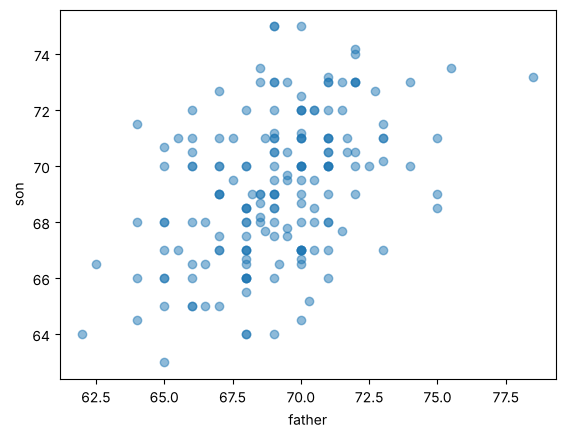

In [4]:
plt.scatter(galton_heights["father"], galton_heights["son"], alpha=0.5)
plt.xlabel("father"); plt.ylabel("son")
plt.show()

In [5]:
galton_heights["father"].corr(galton_heights["son"])

np.float64(0.43849356650023136)

Fit the least squares model. `smf.ols` uses the same formula syntax as R's `lm`:

In [6]:
fit = smf.ols("son ~ father", data=galton_heights).fit()
fit.params

Intercept    38.651452
father        0.442552
dtype: float64

`summary()` is the analog of R's `summary(fit)`:

In [7]:
print(fit.summary())

                            OLS Regression Results                            
Dep. Variable:                    son   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     42.13
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           8.29e-10
Time:                        12:50:12   Log-Likelihood:                -403.34
No. Observations:                 179   AIC:                             810.7
Df Residuals:                     177   BIC:                             817.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     38.6515      4.714      8.199      0.0

Plot $\hat{Y}$ with its 95% confidence band (what `geom_smooth(method = "lm")` draws):

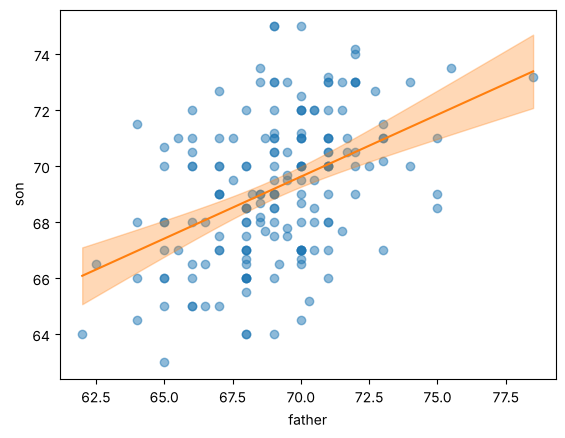

In [8]:
grid = pd.DataFrame({"father": np.linspace(galton_heights["father"].min(),
                                         galton_heights["father"].max(), 100)})
band = fit.get_prediction(grid).summary_frame(alpha=0.05)

plt.scatter(galton_heights["father"], galton_heights["son"], alpha=0.5)
plt.plot(grid["father"], band["mean"], color="C1")
plt.fill_between(grid["father"], band["mean_ci_lower"], band["mean_ci_upper"], color="C1", alpha=0.3)
plt.xlabel("father"); plt.ylabel("son")
plt.show()

`get_prediction` is the analog of `predict(fit, se.fit = TRUE)`: predictions plus standard errors.

In [9]:
pred = fit.get_prediction(galton_heights)
pd.DataFrame({"fit": pred.predicted_mean, "se_fit": pred.se_mean}).head()

,fit,se_fit
0,73.391766,0.663923
1,72.064111,0.469505
2,71.842835,0.437999
3,71.842835,0.437999
4,71.842835,0.437999


## Multiple regression
Fit the full dataset with four predictors. As in R, `gender` is treated as categorical with the first level alphabetically (`female`) as the reference. These estimates match the slides exactly.

In [10]:
fit2 = smf.ols("childHeight ~ mother + father + gender + children", data=galton).fit()
print(fit2.summary())

                            OLS Regression Results                            
Dep. Variable:            childHeight   R-squared:                       0.637
Model:                            OLS   Adj. R-squared:                  0.635
Method:                 Least Squares   F-statistic:                     406.8
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          1.89e-202
Time:                        12:50:13   Log-Likelihood:                -2043.1
No. Observations:                 934   AIC:                             4096.
Df Residuals:                     929   BIC:                             4120.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         17.4310      2.774      6.

**scikit-learn** fits the same model but is built for prediction, not inference: it gives coefficients but no standard errors or p-values. Categorical predictors must be encoded by hand:

In [11]:
from sklearn.linear_model import LinearRegression

X = pd.get_dummies(galton[["mother", "father", "gender", "children"]], drop_first=True, dtype=float)
lr = LinearRegression().fit(X, galton["childHeight"])
pd.Series(np.r_[lr.intercept_, lr.coef_], index=["Intercept"] + list(X.columns)).round(4)

Intercept      17.4310
mother          0.3162
father          0.3852
children       -0.0457
gender_male     5.1985
dtype: float64

## Regression in matrix form
$${\bf y}=X\beta+\epsilon, \qquad \hat\beta = (X'X)^{-1}X'{\bf y}$$
(See the slides for the maximum likelihood derivation.)

In [12]:
X = np.column_stack([np.ones(len(galton_heights)), galton_heights["father"]])
y = galton_heights["son"].to_numpy()

beta_hat = np.linalg.solve(X.T @ X, X.T @ y)   # numerically safer than inverting X'X
beta_hat

array([38.65145228,  0.44255177])

Same answer as `smf.ols` above. Predicted values $\hat y = X\hat\beta$:

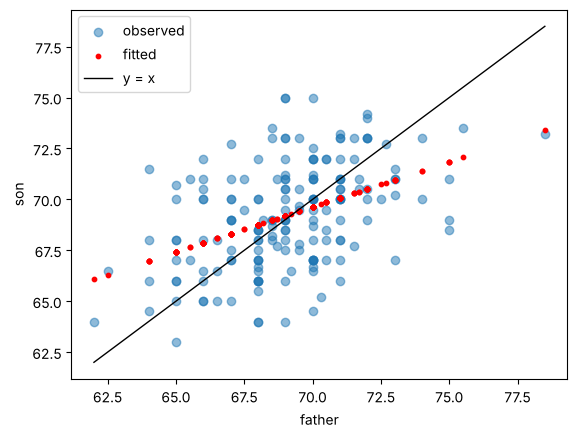

In [13]:
y_hat = X @ beta_hat

plt.scatter(galton_heights["father"], y, alpha=0.5, label="observed")
plt.scatter(galton_heights["father"], y_hat, color="red", s=10, label="fitted")
lims = [galton_heights["father"].min(), galton_heights["father"].max()]
plt.plot(lims, lims, color="black", lw=1, label="y = x")
plt.xlabel("father"); plt.ylabel("son"); plt.legend()
plt.show()

Test statistic for the slope: $t = \hat\beta_1 / (\hat\sigma\sqrt{v_{11}})$, where $v_{11}$ is the diagonal element of $(X'X)^{-1}$ and
$$\hat\sigma^2=\frac{1}{N-p-1}({\bf y}-X{\bf\hat\beta})'({\bf y}-X{\bf\hat\beta}).$$
This mirrors the R code on the slide (where `p` counts both coefficients).

In [14]:
N = len(y)
p = len(beta_hat)
resid = y - X @ beta_hat
sigma2_hat = resid @ resid / (N - p - 1)
V = np.linalg.inv(X.T @ X)
Z2 = beta_hat[1] / np.sqrt(sigma2_hat * V[1, 1])
Z2

np.float64(6.472740999983656)

`statsmodels` uses $N - p$ degrees of freedom with $p$ = 2 coefficients, so its t-value differs very slightly:

In [15]:
fit.tvalues["father"]

np.float64(6.491103422693593)

## The Regression Fallacy
Do Rookie of the Year (ROY) winners suffer a "sophomore slump"?

The batting data come from the R `Lahman` package. We prepared the same tables used on the slides: non-pitcher ROY winners with their rookie and sophomore batting averages, and all non-pitchers with 130+ at bats in both 2013 and 2014.

In [16]:
roy = pd.read_csv(DATA + "lahman_roy.csv")
roy[["nameFirst", "nameLast", "rookie_year", "rookie", "sophomore"]].head()

,nameFirst,nameLast,rookie_year,rookie,sophomore
0,Willie,McCovey,1959,0.354167,0.238462
1,Ichiro,Suzuki,2001,0.349711,0.321484
2,Al,Bumbry,1973,0.337079,0.233333
3,Fred,Lynn,1975,0.331439,0.313609
4,Albert,Pujols,2001,0.328814,0.313559


Proportion of ROYs whose batting average dropped in their sophomore year:

In [17]:
np.mean(roy["sophomore"] - roy["rookie"] <= 0)

np.float64(0.7053571428571429)

Jitters or jinx? Look at **all** players, not just rookies. Top performers of 2013:

In [18]:
two_years = pd.read_csv(DATA + "lahman_batting_2013_2014.csv")
two_years.sort_values("2013", ascending=False).head()

,nameFirst,nameLast,2013,2014
0,Miguel,Cabrera,0.347748,0.312602
1,Hanley,Ramirez,0.345395,0.282851
2,Michael,Cuddyer,0.331288,0.331579
3,Scooter,Gennett,0.323944,0.288636
4,Joe,Mauer,0.323596,0.276923


Most of them drop. And the worst performers of 2013?

In [19]:
two_years.sort_values("2013").head()

,nameFirst,nameLast,2013,2014
311,Danny,Espinosa,0.158228,0.219219
310,Dan,Uggla,0.178571,0.148936
309,Jeff,Mathis,0.181034,0.200000
308,B. J.,Upton,0.184143,0.208092
307,Adam,Rosales,0.190476,0.262195


Their averages mostly go up! The reason: year-to-year correlation is high, but not perfect.

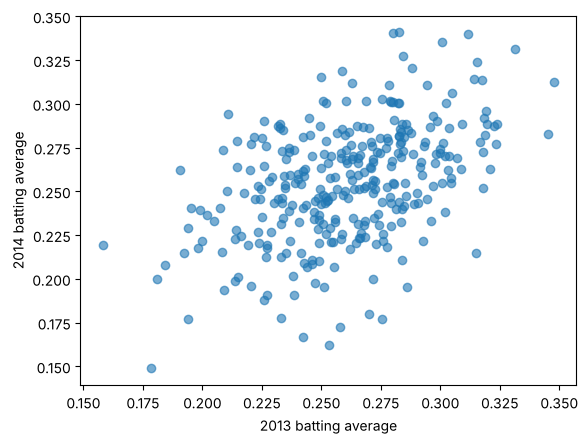

np.float64(0.4602541593197911)

In [20]:
plt.scatter(two_years["2013"], two_years["2014"], alpha=0.6)
plt.xlabel("2013 batting average"); plt.ylabel("2014 batting average")
plt.show()

r = two_years["2013"].corr(two_years["2014"])
r

The data look bivariate normal, so the regression prediction for 2014 is
$$\frac{Y - \mu_Y}{\sigma_Y} = \rho \left( \frac{X - \mu_X}{\sigma_X}\right).$$

In [21]:
mu_x, sd_x = two_years["2013"].mean(), two_years["2013"].std()
mu_y, sd_y = two_years["2014"].mean(), two_years["2014"].std()
print(f"(Y - {mu_y:.3f}) / {sd_y:.3f} = {r:.2f} * (X - {mu_x:.3f}) / {sd_x:.3f}")

# Predicted 2014 average for a .330 hitter in 2013:
x = 0.330
print(f"predicted 2014 for a {x:.3f} hitter: {mu_y + r * sd_y * (x - mu_x) / sd_x:.3f}")

(Y - 0.255) / 0.033 = 0.46 * (X - 0.261) / 0.032
predicted 2014 for a 0.330 hitter: 0.288


Because $\rho < 1$, top performers are predicted to do a bit worse. It's not a jinx, it's **regression to the mean**.

## Session info

In [22]:
import sys, sklearn, matplotlib, statsmodels
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.16
numpy 2.5.3 | pandas 3.0.5 | statsmodels 0.15.0 | scikit-learn 1.9.1 | matplotlib 3.11.2
